# Análisis espacial de actividad pesquera en Shiretoko, Japón

## Objetivo
Analizar la distribución espacial del esfuerzo pesquero aparente y la presencia de embarcaciones en las áreas EBSA 10401 y 10402 de Shiretoko, Japón, utilizando datos de Global Fishing Watch (GFW).

## Procedimiento
1. Cargar y verificar el área de estudio.
2. Consultar datos de esfuerzo pesquero mediante la API de GFW.
3. Consultar datos de presencia de embarcaciones.
4. Homogeneizar los periodos y las áreas geográficas.
5. Generar mapas de distribución espacial.
6. Exportar los resultados para su posterior integración con datos de clorofila-a de Copernicus.



In [2]:

# 1. Importación de bibliotecas

import os
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

print("Bibliotecas cargadas correctamente")


Bibliotecas cargadas correctamente


In [3]:

# 2. Identificar directorio de trabajo y archivos

directorio = Path.cwd()

print("Directorio actual:", directorio)
print("\nArchivos disponibles:")

for archivo in directorio.iterdir():
    print(archivo.name)


Directorio actual: /home/jovyan/tutoriales/17-martes/ohwe26-proy2-python/notebooks

Archivos disponibles:
.ipynb_checkpoints
01_exploracion_area_estudio.ipynb
Prueba-2-GFW.ipynb
02_GFW_descarga_y_mapa.ipynb.ipynb


In [4]:

# 3. Cargar el área de estudio Shiretoko

ruta_geojson = directorio.parent / "Shiretoko_EBSA_10401_10402.geojson"

# Verificar que el archivo existe
print("¿Existe el GeoJSON?", ruta_geojson.exists())

# Cargar geometría
shiretoko = gpd.read_file(ruta_geojson)

# Revisar información
print("\nNúmero de polígonos:", len(shiretoko))
print("\nSistema de coordenadas:", shiretoko.crs)
print("\nTipo de geometrías:")
print(shiretoko.geom_type.value_counts())

# Mostrar atributos
display(shiretoko)


¿Existe el GeoJSON? True

Número de polígonos: 2

Sistema de coordenadas: EPSG:4326

Tipo de geometrías:
MultiPolygon    2
Name: count, dtype: int64


,AreaNumber,AreaName,Municipali,Area,URL,geometry
0,10401.0,"Shiretoko (Shari, Utoro) side coast","Shari, Rausu, Hokkaido Prefecture",215.07212,http://www.env.go.jp/en/nature/biodic/kaiyo-ho...,"MULTIPOLYGON (((145.33396 44.34602, 145.3339 4..."
1,10402.0,Shiretoko (Rausu) side coast,"Shibetsu, Rausu, Hokkaido Prefecture",323.24391,http://www.env.go.jp/en/nature/biodic/kaiyo-ho...,"MULTIPOLYGON (((145.38782 44.34131, 145.38698 ..."


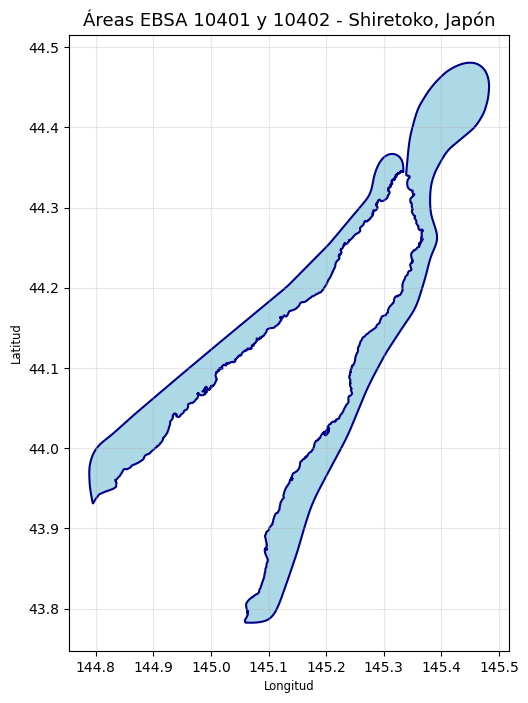

In [5]:

# 4. Visualización preliminar del área de estudio

fig, ax = plt.subplots(figsize=(10, 8))

shiretoko.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="darkblue",
    linewidth=1.5
)

ax.set_title(
    "Áreas EBSA 10401 y 10402 - Shiretoko, Japón",
    fontsize=13
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(alpha=0.3)

plt.show
# 5. Armonización espacial de las áreas EBSA

# Trabajar sobre una copia del GeoJSON original
ebsa = shiretoko.copy()

# Verificar el sistema de coordenadas
print("CRS original:", ebsa.crs)

if ebsa.crs is None:
    raise ValueError("El GeoJSON no tiene CRS definido.")

# Transformar a coordenadas geográficas WGS84
ebsa = ebsa.to_crs("EPSG:4326")

# Verificar geometrías
print("\nGeometrías válidas:")
print(ebsa.geometry.is_valid)

if not ebsa.geometry.is_valid.all():
    raise ValueError("Hay geometrías inválidas. Revisar antes de continuar.")

# Crear una geometría conjunta sin perder los polígonos originales
area_union = ebsa.geometry.unary_union

# Crear GeoDataFrame de la unión
area_estudio = gpd.GeoDataFrame(
    {"nombre": ["Shiretoko_EBSA_10401_10402"]},
    geometry=[area_union],
    crs="EPSG:4326"
)

# Calcular superficie en una proyección equivalente
ebsa_area = ebsa.to_crs("EPSG:6933")
union_area = area_estudio.to_crs("EPSG:6933")

ebsa["area_km2"] = ebsa_area.geometry.area / 1_000_000
area_estudio["area_km2"] = union_area.geometry.area / 1_000_000

# Revisar resultados
print("\nNúmero de áreas EBSA:", len(ebsa))
print("Número de geometrías en la unión:", len(area_estudio))

print("\nSuperficie individual:")
display(ebsa[["area_km2"]])

print("\nSuperficie total de la unión:")
display(area_estudio[["nombre", "area_km2"]])

print("\nExtensión geográfica:")
print(area_estudio.total_bounds)



In [6]:

# 5. Armonización espacial de las áreas EBSA

# Trabajar sobre una copia del GeoJSON original
ebsa = shiretoko.copy()

# Verificar el sistema de coordenadas
print("CRS original:", ebsa.crs)

if ebsa.crs is None:
    raise ValueError("El GeoJSON no tiene CRS definido.")

# Transformar a coordenadas geográficas WGS84
ebsa = ebsa.to_crs("EPSG:4326")

# Verificar geometrías
print("\nGeometrías válidas:")
print(ebsa.geometry.is_valid)

if not ebsa.geometry.is_valid.all():
    raise ValueError("Hay geometrías inválidas. Revisar antes de continuar.")

# Crear una geometría conjunta sin perder los polígonos originales
area_union = ebsa.geometry.unary_union

# Crear GeoDataFrame de la unión
area_estudio = gpd.GeoDataFrame(
    {"nombre": ["Shiretoko_EBSA_10401_10402"]},
    geometry=[area_union],
    crs="EPSG:4326"
)

# Calcular superficie en una proyección equivalente
ebsa_area = ebsa.to_crs("EPSG:6933")
union_area = area_estudio.to_crs("EPSG:6933")

ebsa["area_km2"] = ebsa_area.geometry.area / 1_000_000
area_estudio["area_km2"] = union_area.geometry.area / 1_000_000

# Revisar resultados
print("\nNúmero de áreas EBSA:", len(ebsa))
print("Número de geometrías en la unión:", len(area_estudio))

print("\nSuperficie individual:")
display(ebsa[["area_km2"]])

print("\nSuperficie total de la unión:")
display(area_estudio[["nombre", "area_km2"]])

print("\nExtensión geográfica:")
print(area_estudio.total_bounds)


CRS original: EPSG:4326

Geometrías válidas:
0    True
1    True
dtype: bool

Número de áreas EBSA: 2
Número de geometrías en la unión: 1

Superficie individual:


/tmp/ipykernel_869/910765356.py:23: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  area_union = ebsa.geometry.unary_union


,area_km2
0,215.033544
1,323.247792



Superficie total de la unión:


,nombre,area_km2
0,Shiretoko_EBSA_10401_10402,538.281336



Extensión geográfica:
[144.78856639  43.78250393 145.48289701  44.48055712]


In [7]:

# 6. Guardar geometrías armonizadas

# Crear directorio de resultados
ruta_salida = directorio.parent / "datos" / "procesados" / "espacial"
ruta_salida.mkdir(parents=True, exist_ok=True)

# Guardar las dos áreas por separado
ebsa.to_file(
    ruta_salida / "shiretoko_ebsa_individuales.geojson",
    driver="GeoJSON"
)

# Guardar la unión de ambas áreas
area_estudio.to_file(
    ruta_salida / "shiretoko_ebsa_union.geojson",
    driver="GeoJSON"
)

print("Archivos espaciales guardados correctamente.")

print("\nArchivos generados:")
for archivo in ruta_salida.iterdir():
    print(archivo.name)


Archivos espaciales guardados correctamente.

Archivos generados:
shiretoko_ebsa_individuales.geojson
shiretoko_ebsa_union.geojson


In [8]:
# 1. Crear la geometría conjunta de las dos áreas EBSA
area_union = ebsa.geometry.union_all()

# 2. Crear un GeoDataFrame con una sola área de estudio
area_gfw = gpd.GeoDataFrame(
    {"nombre": ["Shiretoko_EBSA_10401_10402"]},
    geometry=[area_union],
    crs=ebsa.crs
)

# 3. Asegurar el sistema de coordenadas WGS84
area_gfw = area_gfw.to_crs("EPSG:4326")

# 4. Comprobar la superficie en una proyección métrica
area_utm = area_gfw.to_crs("EPSG:32655")

print("CRS:", area_gfw.crs)
print("Geometría:", area_gfw.geometry.iloc[0].geom_type)
print("Área total (km²):", area_utm.area.iloc[0] / 1e6)

# 5. Exportar el área de estudio
area_gfw.to_file(
    "Shiretoko_EBSA_10401_10402.geojson",
    driver="GeoJSON"
)

print("Archivo GeoJSON generado correctamente")

CRS: EPSG:4326
Geometría: MultiPolygon
Área total (km²): 538.1684322315735
Archivo GeoJSON generado correctamente


In [9]:
import inspect

print(
    inspect.signature(
        gfw_client.fourwings.create_fishing_effort_report
    )
)

NameError: name 'gfw_client' is not defined

In [10]:
import gfwapiclient as gfw
from getpass import getpass

GFW_TOKEN = getpass("Introduce tu API token de GFW: ")

gfw_client = gfw.Client(
    access_token=GFW_TOKEN
)

print("Conexión con GFW inicializada")

ModuleNotFoundError: No module named 'gfwapiclient'

In [11]:
%pip install gfw-api-python-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 92.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 989.6/989.6 kB 29.6 MB/s  0:00:00
  Attempting uninstall: python-dotenv
    Found existing installation: python-dotenv 1.2.1
    Uninstalling python-dotenv-1.2.1:
      Successfully uninstalled python-dotenv-1.2.1
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.1
    Uninstalling pandas-3.0.1:━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/7 [pandas]
      Successfully uninstalled pandas-3.0.1━━━━━━━━━━━━━━━━━━━━━━━ 2/7 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [gfw-api-python-client]ntic-settings]
Note: you may need to restart the kernel to use updated packages.


In [12]:
import gfwapiclient as gfw

print("Biblioteca GFW instalada correctamente")


Biblioteca GFW instalada correctamente


In [13]:
from getpass import getpass

GFW_TOKEN = getpass("Introduce tu API token de GFW: ")

gfw_client = gfw.Client(
    access_token=GFW_TOKEN
)

print("Conexión con GFW inicializada")


Introduce tu API token de GFW:  ········


Conexión con GFW inicializada


In [14]:

%pip install gfw-api-python-client


Note: you may need to restart the kernel to use updated packages.


In [15]:

import gfwapiclient as gfw

print("Versión instalada:", gfw.__version__)
print("Biblioteca GFW cargada correctamente")



Versión instalada: 1.4.0
Biblioteca GFW cargada correctamente


In [16]:

from getpass import getpass

GFW_TOKEN = getpass("Introduce tu API token de GFW: ")

gfw_client = gfw.Client(
    access_token=GFW_TOKEN
)

print("Cliente de Global Fishing Watch inicializado")


Introduce tu API token de GFW:  ········


Cliente de Global Fishing Watch inicializado


In [17]:

# Verificar que tenemos la geometría de Shiretoko

print("Geometría disponible:", type(area_union))
print("Extensión:", area_union.bounds)

# Convertir a formato GeoJSON
geojson_shiretoko = area_union.__geo_interface__

print("GeoJSON preparado correctamente")


Geometría disponible: <class 'shapely.geometry.multipolygon.MultiPolygon'>
Extensión: (144.78856638803074, 43.78250393162841, 145.48289700637577, 44.480557123744234)
GeoJSON preparado correctamente


In [18]:

# Primera consulta de esfuerzo pesquero AIS
# Shiretoko: EBSA 10401 + 10402

resultado_gfw = await gfw_client.fourwings.create_fishing_effort_report(
    spatial_resolution="LOW",
    temporal_resolution="MONTHLY",
    start_date="2024-01-01",
    end_date="2024-12-31",
    geojson=geojson_shiretoko
)

print("Consulta completada")
print("Tipo de resultado:", type(resultado_gfw))
print(resultado_gfw)


Consulta completada
Tipo de resultado: <class 'gfwapiclient.resources.fourwings.report.models.response.FourWingsReportResult'>


In [19]:

# Convertir respuesta de GFW a DataFrame

df_gfw = resultado_gfw.df()

# Revisar dimensiones
print("Dimensiones de la base:", df_gfw.shape)

# Revisar columnas
print("\nColumnas disponibles:")
print(df_gfw.columns.tolist())

# Mostrar primeros registros
display(df_gfw.head(10))

# Revisar cantidad de registros
print("\nTotal de registros:", len(df_gfw))


Dimensiones de la base: (25, 20)

Columnas disponibles:
['date', 'detections', 'flag', 'gear_type', 'hours', 'vessel_ids', 'vessel_id', 'vessel_type', 'entry_timestamp', 'exit_timestamp', 'first_transmission_date', 'last_transmission_date', 'imo', 'mmsi', 'call_sign', 'dataset', 'report_dataset', 'ship_name', 'lat', 'lon']


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,first_transmission_date,last_transmission_date,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon
0,2024-10,None,None,None,0.698889,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
1,2024-08,None,None,None,0.949722,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.5,145.4
2,2024-08,None,None,None,25.602500,3,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,144.9
3,2024-09,None,None,None,4.146389,2,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
4,2024-08,None,None,None,3.109444,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
5,2024-10,None,None,None,9.706667,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,145.2
6,2024-08,None,None,None,0.783333,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.4,145.4
7,2024-07,None,None,None,4.375000,2,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.0
8,2024-07,None,None,None,24.675278,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.9
9,2024-09,None,None,None,3.679722,2,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.9



Total de registros: 25


In [20]:

# Diagnóstico de la respuesta de GFW

print("DIMENSIONES:", df_gfw.shape)

print("\nTIPOS DE DATOS:")
print(df_gfw.dtypes)

print("\nVALORES NULOS:")
print(df_gfw.isnull().sum())

print("\nESTADÍSTICAS DE VARIABLES PRINCIPALES:")
display(
    df_gfw[["date", "detections", "hours", "lat", "lon"]]
    .describe(include="all")
)

print("\nPRIMEROS 10 REGISTROS:")
display(
    df_gfw[["date", "detections", "hours", "lat", "lon"]]
    .head(10)
)


DIMENSIONES: (25, 20)

TIPOS DE DATOS:
date                           str
detections                  object
flag                        object
gear_type                   object
hours                      float64
vessel_ids                   int64
vessel_id                   object
vessel_type                 object
entry_timestamp             object
exit_timestamp              object
first_transmission_date     object
last_transmission_date      object
imo                         object
mmsi                        object
call_sign                   object
dataset                     object
report_dataset                 str
ship_name                   object
lat                        float64
lon                        float64
dtype: object

VALORES NULOS:
date                        0
detections                 25
flag                       25
gear_type                  25
hours                       0
vessel_ids                  0
vessel_id                  25
vessel_type          

,date,detections,hours,lat,lon
count,25,0,25.000000,25.000000,25.000000
unique,7,0,NaN,NaN,NaN
top,2024-08,NaN,NaN,NaN,NaN
freq,6,NaN,NaN,NaN,NaN
mean,NaN,NaN,6.228378,44.180000,145.080000
std,NaN,NaN,8.475927,0.206155,0.246644
min,NaN,NaN,0.698889,44.000000,144.800000
25%,NaN,NaN,1.055000,44.000000,144.900000
50%,NaN,NaN,3.109444,44.100000,145.000000
75%,NaN,NaN,4.375000,44.400000,145.400000



PRIMEROS 10 REGISTROS:


,date,detections,hours,lat,lon
0,2024-10,None,0.698889,44.0,144.8
1,2024-08,None,0.949722,44.5,145.4
2,2024-08,None,25.602500,44.1,144.9
3,2024-09,None,4.146389,44.0,144.8
4,2024-08,None,3.109444,44.0,144.8
5,2024-10,None,9.706667,44.0,145.2
6,2024-08,None,0.783333,44.4,145.4
7,2024-07,None,4.375000,44.1,145.0
8,2024-07,None,24.675278,44.0,144.9
9,2024-09,None,3.679722,44.0,144.9


In [21]:
display(df.head(25).T)


NameError: name 'df' is not defined

In [22]:
print("Meses disponibles:")
print(df["date"].value_counts().sort_index())

Meses disponibles:


NameError: name 'df' is not defined

In [23]:
print("Valores de vessel_ids:")
print(df["vessel_ids"].describe())

print("\nValores únicos:")
print(df["vessel_ids"].unique())

Valores de vessel_ids:


NameError: name 'df' is not defined

In [24]:
display(df_gfw.head(25).T)

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
date,2024-10,2024-08,2024-08,2024-09,2024-08,2024-10,2024-08,2024-07,2024-07,2024-09,...,2024-10,2024-06,2024-04,2024-05,2024-05,2024-04,2024-06,2024-05,2024-07,2024-07
detections,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
flag,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
gear_type,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
hours,0.698889,0.949722,25.6025,4.146389,3.109444,9.706667,0.783333,4.375,24.675278,3.679722,...,20.351667,3.571667,2.608611,3.429444,0.743056,7.707778,0.9625,1.623056,3.305833,1.041667
vessel_ids,1,1,3,2,1,1,1,2,1,2,...,1,1,1,1,1,1,1,1,3,1
vessel_id,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
vessel_type,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
entry_timestamp,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
exit_timestamp,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None


In [25]:
print("Meses disponibles:")
print(df_gfw["date"].value_counts().sort_index())

Meses disponibles:
date
2024-04    2
2024-05    3
2024-06    2
2024-07    5
2024-08    6
2024-09    3
2024-10    4
Name: count, dtype: int64


In [26]:
print("Valores de vessel_ids:")
print(df_gfw["vessel_ids"].describe())

print("\nValores únicos:")
print(df_gfw["vessel_ids"].unique())


Valores de vessel_ids:
count    25.000000
mean      1.320000
std       0.627163
min       1.000000
25%       1.000000
50%       1.000000
75%       1.000000
max       3.000000
Name: vessel_ids, dtype: float64

Valores únicos:
[1 3 2]


In [27]:
# Crear identificador de cada celda espacial
df_gfw["celda"] = (
    df_gfw["lat"].astype(str) + "_" +
    df_gfw["lon"].astype(str)
)

# Resumen mensual
resumen_mensual = (
    df_gfw.groupby("date")
    .agg(
        registros=("date", "size"),
        horas_esfuerzo=("hours", "sum"),
        celdas_espaciales=("celda", "nunique")
    )
    .reset_index()
)

display(resumen_mensual)

,date,registros,horas_esfuerzo,celdas_espaciales
0,2024-04,2,10.316389,2
1,2024-05,3,5.795556,3
2,2024-06,2,4.534167,2
3,2024-07,5,34.924444,5
4,2024-08,6,59.301389,6
5,2024-09,3,9.025278,3
6,2024-10,4,31.812222,4


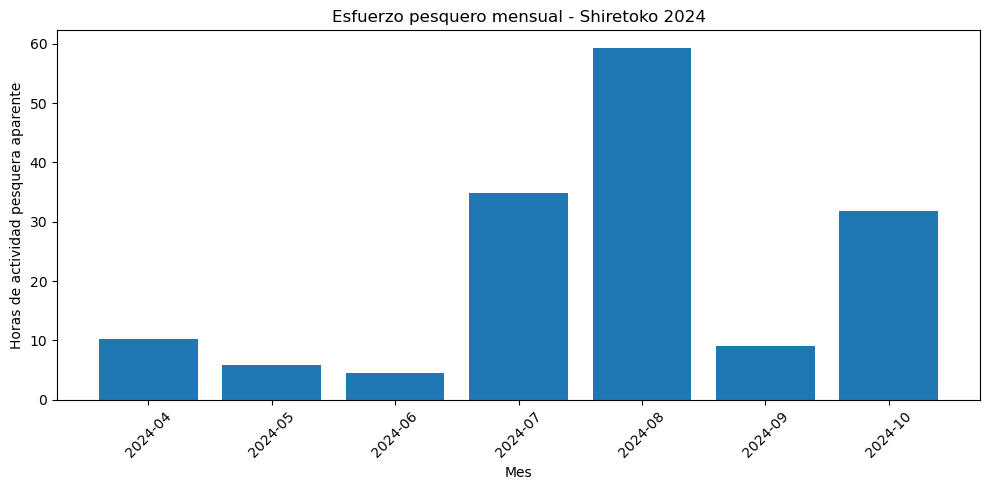

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    resumen_mensual["date"],
    resumen_mensual["horas_esfuerzo"]
)

plt.title("Esfuerzo pesquero mensual - Shiretoko 2024")
plt.xlabel("Mes")
plt.ylabel("Horas de actividad pesquera aparente")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
# Agregar horas de esfuerzo por ubicación
resumen_espacial = (
    df_gfw.groupby(["lat", "lon"])
    .agg(
        horas_totales=("hours", "sum"),
        registros=("hours", "count"),
        meses=("date", "nunique")
    )
    .reset_index()
)

# Ordenar de mayor a menor esfuerzo
resumen_espacial = resumen_espacial.sort_values(
    "horas_totales",
    ascending=False
)

display(resumen_espacial)

,lat,lon,horas_totales,registros,meses
4,44.1,145.0,53.230556,4,4
1,44.0,144.9,30.961667,4,4
3,44.1,144.9,28.908333,2,2
0,44.0,144.8,17.285556,5,5
2,44.0,145.2,9.706667,1,1
7,44.5,145.4,6.305556,5,5
6,44.4,145.4,5.881667,3,3
5,44.2,145.2,3.429444,1,1


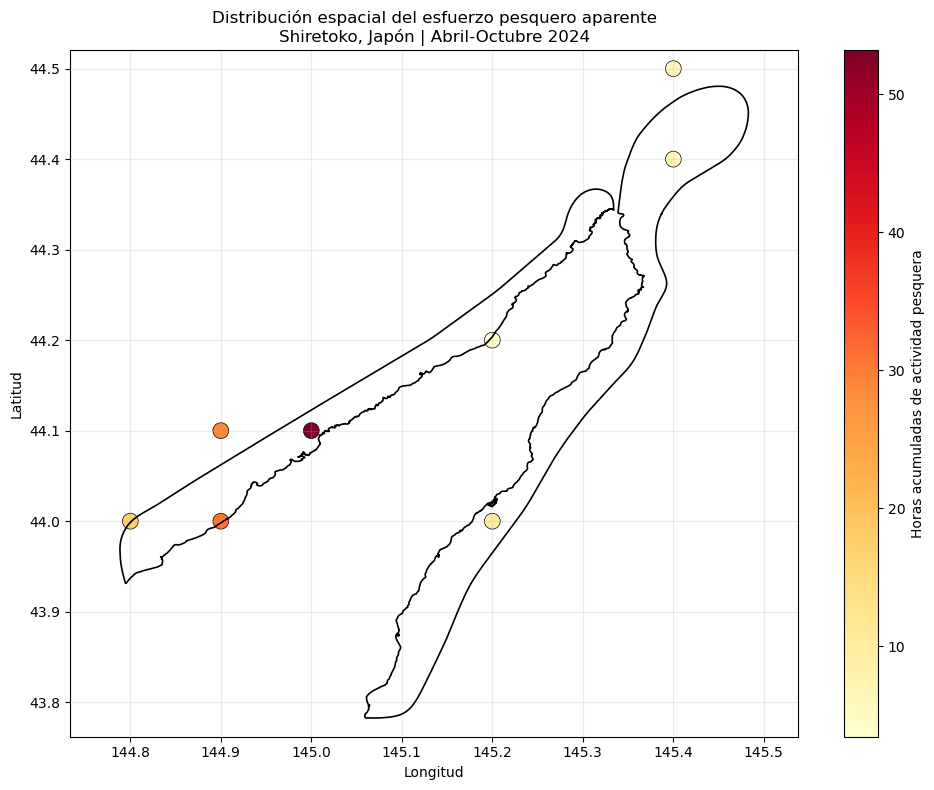

In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

# Dibujar el límite del área de estudio
poligonos = getattr(area_union, "geoms", [area_union])

for poligono in poligonos:
    x, y = poligono.exterior.xy
    ax.plot(x, y, color="black", linewidth=1.2)

# Representar las horas de actividad pesquera
puntos = ax.scatter(
    resumen_espacial["lon"],
    resumen_espacial["lat"],
    c=resumen_espacial["horas_totales"],
    cmap="YlOrRd",
    s=130,
    edgecolors="black",
    linewidths=0.5
)

# Barra de color
cbar = plt.colorbar(puntos, ax=ax)
cbar.set_label("Horas acumuladas de actividad pesquera")

ax.set_title(
    "Distribución espacial del esfuerzo pesquero aparente\n"
    "Shiretoko, Japón | Abril-Octubre 2024"
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.grid(alpha=0.25)
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()
plt.show()

In [31]:
print("Cinco ubicaciones con mayor esfuerzo:")

display(
    resumen_espacial.head(5)
)

Cinco ubicaciones con mayor esfuerzo:


,lat,lon,horas_totales,registros,meses
4,44.1,145.0,53.230556,4,4
1,44.0,144.9,30.961667,4,4
3,44.1,144.9,28.908333,2,2
0,44.0,144.8,17.285556,5,5
2,44.0,145.2,9.706667,1,1


In [32]:

# Resumen mensual del esfuerzo pesquero aparente

resumen_mensual = (
    df_gfw.groupby("date")
    .agg(
        horas_totales=("hours", "sum"),
        registros=("hours", "count"),
        horas_promedio=("hours", "mean"),
        horas_maximas=("hours", "max")
    )
    .reset_index()
    .sort_values("date")
)

print("Distribución mensual del esfuerzo:")
display(resumen_mensual)



Distribución mensual del esfuerzo:


,date,horas_totales,registros,horas_promedio,horas_maximas
0,2024-04,10.316389,2,5.158194,7.707778
1,2024-05,5.795556,3,1.931852,3.429444
2,2024-06,4.534167,2,2.267083,3.571667
3,2024-07,34.924444,5,6.984889,24.675278
4,2024-08,59.301389,6,9.883565,27.304722
5,2024-09,9.025278,3,3.008426,4.146389
6,2024-10,31.812222,4,7.953056,20.351667


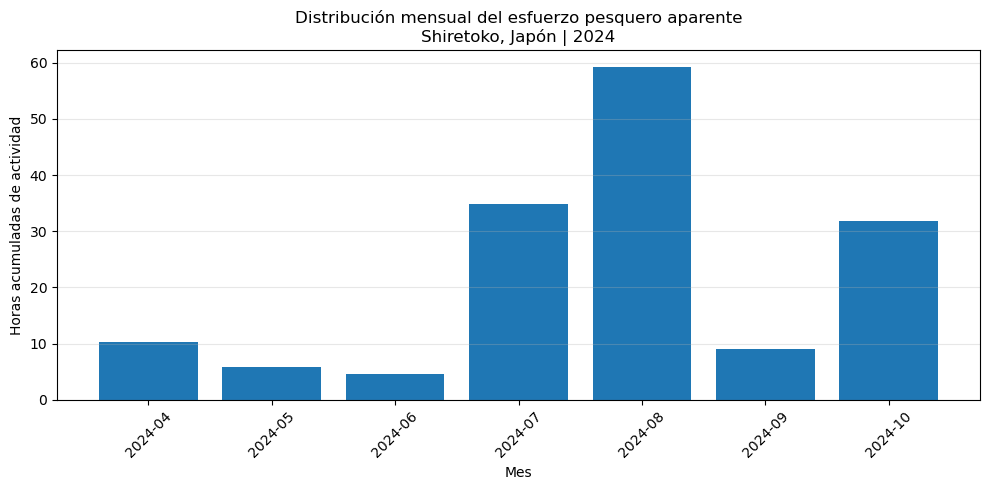

In [33]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    resumen_mensual["date"],
    resumen_mensual["horas_totales"]
)

plt.title("Distribución mensual del esfuerzo pesquero aparente\nShiretoko, Japón | 2024")
plt.xlabel("Mes")
plt.ylabel("Horas acumuladas de actividad")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [34]:

# CONSULTA 1: ESFUERZO PESQUERO APARENTE 2020
# Región: Shiretoko, Japón
# Resolución: LOW
# Temporalidad: MONTHLY

resultado_2020 = await gfw_client.fourwings.create_fishing_effort_report(
    spatial_resolution="LOW",
    temporal_resolution="MONTHLY",
    start_date="2020-01-01",
    end_date="2021-01-01",
    geojson=geojson_shiretoko
)

# Convertir resultado a DataFrame
df_2020 = resultado_2020.df()

# Revisar resultados
print("CONSULTA 2020 COMPLETADA")
print("Dimensiones:", df_2020.shape)
print("Meses disponibles:", sorted(df_2020["date"].unique()))
print("Horas totales:", df_2020["hours"].sum())

display(df_2020.head())


CONSULTA 2020 COMPLETADA
Dimensiones: (5, 20)
Meses disponibles: ['2020-04', '2020-07', '2020-09']
Horas totales: 92.14249999999998


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,first_transmission_date,last_transmission_date,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon
0,2020-07,None,None,None,0.970556,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.4,145.4
1,2020-09,None,None,None,9.460278,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.2,145.4
2,2020-09,None,None,None,20.724167,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.3
3,2020-04,None,None,None,52.052222,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
4,2020-09,None,None,None,8.935278,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.3,145.4


In [35]:

# VALIDACIÓN DE COBERTURA TEMPORAL Y ESPACIAL 2020

import pandas as pd

# Resumen mensual
resumen_2020 = (
    df_2020.groupby("date")
    .agg(
        horas_reportadas=("hours", "sum"),
        registros=("hours", "count")
    )
    .reset_index()
    .sort_values("date")
)

print("RESUMEN MENSUAL 2020")
display(resumen_2020)

# Cobertura de los 12 meses
meses_2020 = pd.period_range(
    start="2020-01",
    end="2020-12",
    freq="M"
).astype(str)

cobertura_2020 = (
    resumen_2020.set_index("date")
    .reindex(meses_2020)
    .rename_axis("mes")
    .reset_index()
)

print("COBERTURA DE LOS 12 MESES")
display(cobertura_2020)

# Distribución espacial
print("UBICACIONES REGISTRADAS")
display(
    df_2020[["lat", "lon", "hours"]]
    .sort_values("hours", ascending=False)
)

print("Número de ubicaciones únicas:",
      df_2020[["lat", "lon"]].drop_duplicates().shape[0])


RESUMEN MENSUAL 2020


,date,horas_reportadas,registros
0,2020-04,52.052222,1
1,2020-07,0.970556,1
2,2020-09,39.119722,3


COBERTURA DE LOS 12 MESES


,mes,horas_reportadas,registros
0,2020-01,NaN,NaN
1,2020-02,NaN,NaN
2,2020-03,NaN,NaN
3,2020-04,52.052222,1.0
4,2020-05,NaN,NaN
5,2020-06,NaN,NaN
6,2020-07,0.970556,1.0
7,2020-08,NaN,NaN
8,2020-09,39.119722,3.0
9,2020-10,NaN,NaN


UBICACIONES REGISTRADAS


,lat,lon,hours
3,44.0,144.8,52.052222
2,44.1,145.3,20.724167
1,44.2,145.4,9.460278
4,44.3,145.4,8.935278
0,44.4,145.4,0.970556


Número de ubicaciones únicas: 5


In [36]:

# CONSULTA 2: ESFUERZO PESQUERO APARENTE 2021

resultado_2021 = await gfw_client.fourwings.create_fishing_effort_report(
    spatial_resolution="LOW",
    temporal_resolution="MONTHLY",
    start_date="2021-01-01",
    end_date="2022-01-01",
    geojson=geojson_shiretoko
)

df_2021 = resultado_2021.df()

print("CONSULTA 2021 COMPLETADA")
print("Dimensiones:", df_2021.shape)
print("Meses disponibles:", sorted(df_2021["date"].unique()))
print("Horas totales:", df_2021["hours"].sum())

display(df_2021.head())


CONSULTA 2021 COMPLETADA
Dimensiones: (2, 20)
Meses disponibles: ['2021-04']
Horas totales: 7.454444444444444


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,first_transmission_date,last_transmission_date,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon
0,2021-04,None,None,None,6.742500,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
1,2021-04,None,None,None,0.711944,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.9


In [39]:
# CONSULTA DE ESFUERZO PESQUERO AIS - 2021
# Shiretoko, Japón

resultado_2021 = await gfw_client.fourwings.create_fishing_effort_report(
    spatial_resolution="Low",
    temporal_resolution="MONTHLY",
    start_date="2021-01-01",
    end_date="2021-12-31",
    geojson=geojson_shiretoko
)

print("CONSULTA 2022 COMPLETADA")
print("Tipo de resultado:", type(resultado_2021))

RequestParamsValidationError: 4Wings report request params validation failed. Errors:
 Input should be 'LOW' or 'HIGH': [loc=('spatial_resolution',), type=enum, input=Low]

In [41]:

# CONSULTA DE ESFUERZO PESQUERO AIS - 2022
# Shiretoko, Japón

resultado_2022 = await gfw_client.fourwings.create_fishing_effort_report(
    spatial_resolution="LOW",
    temporal_resolution="MONTHLY",
    start_date="2022-01-01",
    end_date="2022-12-31",
    geojson=geojson_shiretoko
)

print("CONSULTA 2022 COMPLETADA")
print("Tipo de resultado:", type(resultado_2022))



CONSULTA 2022 COMPLETADA
Tipo de resultado: <class 'gfwapiclient.resources.fourwings.report.models.response.FourWingsReportResult'>


In [42]:

# Extraer los datos de la consulta 2022

df_2022 = resultado_2022.to_df()

print("DIMENSIONES:", df_2022.shape)

print("\nMESES DISPONIBLES:")
print(df_2022["date"].value_counts().sort_index())

print("\nHORAS TOTALES:")
print(df_2022["hours"].sum())

display(df_2022.head())


AttributeError: 'FourWingsReportResult' object has no attribute 'to_df'

In [43]:

# Extraer los datos de la consulta 2022

df_2022 = resultado_2022.df()

print("DIMENSIONES:", df_2022.shape)

print("\nMESES DISPONIBLES:")
print(df_2022["date"].value_counts().sort_index())

print("\nHORAS TOTALES:")
print(df_2022["hours"].sum())

print("\nPRIMEROS REGISTROS:")
display(df_2022.head())


DIMENSIONES: (11, 20)

MESES DISPONIBLES:
date
2022-06    1
2022-07    2
2022-08    1
2022-10    2
2022-11    2
2022-12    3
Name: count, dtype: int64

HORAS TOTALES:
29.186002777777777

PRIMEROS REGISTROS:


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,first_transmission_date,last_transmission_date,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon
0,2022-11,None,None,None,0.749722,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.0
1,2022-07,None,None,None,1.816111,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.4,145.4
2,2022-12,None,None,None,2.801111,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.0
3,2022-08,None,None,None,0.493889,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.0
4,2022-10,None,None,None,4.592778,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.0


In [44]:

# CONSULTA DE ESFUERZO PESQUERO AIS - 2023
# Shiretoko, Japón

resultado_2023 = await gfw_client.fourwings.create_fishing_effort_report(
    spatial_resolution="LOW",
    temporal_resolution="MONTHLY",
    start_date="2023-01-01",
    end_date="2023-12-31",
    geojson=geojson_shiretoko
)

print("CONSULTA 2023 COMPLETADA")
print("Tipo de resultado:", type(resultado_2023))




CONSULTA 2023 COMPLETADA
Tipo de resultado: <class 'gfwapiclient.resources.fourwings.report.models.response.FourWingsReportResult'>


In [45]:

# Extraer los datos de 2023

df_2023 = resultado_2023.df()

print("DIMENSIONES:", df_2023.shape)

print("\nMESES DISPONIBLES:")
print(df_2023["date"].value_counts().sort_index())

print("\nHORAS TOTALES:")
print(df_2023["hours"].sum())

print("\nPRIMEROS REGISTROS:")
display(df_2023.head())


DIMENSIONES: (24, 20)

MESES DISPONIBLES:
date
2023-04    3
2023-05    1
2023-06    4
2023-07    6
2023-08    6
2023-09    2
2023-10    1
2023-12    1
Name: count, dtype: int64

HORAS TOTALES:
302.8283333333334

PRIMEROS REGISTROS:


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,first_transmission_date,last_transmission_date,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon
0,2023-07,None,None,None,55.937778,7,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.0
1,2023-07,None,None,None,39.785000,6,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.9
2,2023-12,None,None,None,20.362222,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
3,2023-08,None,None,None,15.773611,6,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
4,2023-10,None,None,None,4.178611,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8


In [46]:

# CONSULTA DE ESFUERZO PESQUERO AIS - 2024
# Shiretoko, Japón

resultado_2024 = await gfw_client.fourwings.create_fishing_effort_report(
    spatial_resolution="LOW",
    temporal_resolution="MONTHLY",
    start_date="2024-01-01",
    end_date="2024-12-31",
    geojson=geojson_shiretoko
)

print("CONSULTA 2024 COMPLETADA")
print("Tipo de resultado:", type(resultado_2024))



CONSULTA 2024 COMPLETADA
Tipo de resultado: <class 'gfwapiclient.resources.fourwings.report.models.response.FourWingsReportResult'>


In [47]:

# Extraer los datos de 2024

df_2024 = resultado_2024.df()

print("DIMENSIONES:", df_2024.shape)

print("\nMESES DISPONIBLES:")
print(df_2024["date"].value_counts().sort_index())

print("\nHORAS TOTALES:")
print(df_2024["hours"].sum())

print("\nPRIMEROS REGISTROS:")
display(df_2024.head())


DIMENSIONES: (25, 20)

MESES DISPONIBLES:
date
2024-04    2
2024-05    3
2024-06    2
2024-07    5
2024-08    6
2024-09    3
2024-10    4
Name: count, dtype: int64

HORAS TOTALES:
155.70944444444444

PRIMEROS REGISTROS:


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,first_transmission_date,last_transmission_date,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon
0,2024-08,None,None,None,3.109444,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
1,2024-10,None,None,None,9.706667,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,145.2
2,2024-08,None,None,None,0.949722,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.5,145.4
3,2024-09,None,None,None,4.146389,2,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8
4,2024-10,None,None,None,0.698889,1,None,None,None,None,None,None,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8


In [48]:
# Estandarizar el nombre del DataFrame 2024
df_2024 = df_gfw

# Integrar los resultados de los cinco años
bases_anuales = {
    2020: df_2020,
    2021: df_2021,
    2022: df_2022,
    2023: df_2023,
    2024: df_2024
}

# Agregar el año a cada registro
for anio, base in bases_anuales.items():
    base["anio"] = anio

# Unir todas las bases
df_consolidado = pd.concat(
    bases_anuales.values(),
    ignore_index=True
)

print("DIMENSIONES DE LA BASE CONSOLIDADA:")
print(df_consolidado.shape)

display(df_consolidado.head())

DIMENSIONES DE LA BASE CONSOLIDADA:
(67, 22)


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,...,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon,anio,celda
0,2020-07,None,None,None,0.970556,1,None,None,None,None,...,None,None,None,None,public-global-fishing-effort:v5.0,None,44.4,145.4,2020,NaN
1,2020-09,None,None,None,9.460278,1,None,None,None,None,...,None,None,None,None,public-global-fishing-effort:v5.0,None,44.2,145.4,2020,NaN
2,2020-09,None,None,None,20.724167,1,None,None,None,None,...,None,None,None,None,public-global-fishing-effort:v5.0,None,44.1,145.3,2020,NaN
3,2020-04,None,None,None,52.052222,1,None,None,None,None,...,None,None,None,None,public-global-fishing-effort:v5.0,None,44.0,144.8,2020,NaN
4,2020-09,None,None,None,8.935278,1,None,None,None,None,...,None,None,None,None,public-global-fishing-effort:v5.0,None,44.3,145.4,2020,NaN


In [49]:
# 1. Registros por año
print("REGISTROS POR AÑO:")
print(df_consolidado["anio"].value_counts().sort_index())

# 2. Horas acumuladas por año
print("\nHORAS DE ESFUERZO POR AÑO:")
print(
    df_consolidado.groupby("anio")["hours"]
    .sum()
)

# 3. Verificar valores nulos
print("\nVALORES NULOS:")
print(df_consolidado[["date", "hours", "lat", "lon", "anio"]].isnull().sum())

# 4. Verificar coordenadas
print("\nRANGO DE COORDENADAS:")
print(df_consolidado[["lat", "lon"]].describe())

# 5. Registros duplicados
print("\nREGISTROS DUPLICADOS:")
print(df_consolidado.duplicated().sum())

REGISTROS POR AÑO:
anio
2020     5
2021     2
2022    11
2023    24
2024    25
Name: count, dtype: int64

HORAS DE ESFUERZO POR AÑO:
anio
2020     92.142500
2021      7.454444
2022     29.186003
2023    302.828333
2024    155.709444
Name: hours, dtype: float64

VALORES NULOS:
date     0
hours    0
lat      0
lon      0
anio     0
dtype: int64

RANGO DE COORDENADAS:
             lat         lon
count  67.000000   67.000000
mean   44.146269  145.056716
std     0.174363    0.224435
min    44.000000  144.800000
25%    44.000000  144.900000
50%    44.100000  145.000000
75%    44.200000  145.250000
max    44.500000  145.400000

REGISTROS DUPLICADOS:
0


In [50]:
# Agrupar esfuerzo por ubicación y año

esfuerzo_espacial_anual = (
    df_consolidado
    .groupby(["lat", "lon", "anio"], as_index=False)
    .agg(
        horas_totales=("hours", "sum"),
        registros=("hours", "count"),
        meses=("date", "nunique")
    )
)

print("DIMENSIONES:")
print(esfuerzo_espacial_anual.shape)

print("\nPRIMEROS REGISTROS:")
display(esfuerzo_espacial_anual.head(10))

DIMENSIONES:
(29, 6)

PRIMEROS REGISTROS:


,lat,lon,anio,horas_totales,registros,meses
0,44.0,144.8,2020,52.052222,1,1
1,44.0,144.8,2021,6.742500,1,1
2,44.0,144.8,2023,76.901389,7,7
3,44.0,144.8,2024,17.285556,5,5
4,44.0,144.9,2021,0.711944,1,1
5,44.0,144.9,2023,61.565278,4,4
6,44.0,144.9,2024,30.961667,4,4
7,44.0,145.2,2022,4.805169,1,1
8,44.0,145.2,2024,9.706667,1,1
9,44.1,144.9,2023,73.879444,3,3


In [51]:
# Esfuerzo acumulado por ubicación durante 2020-2024

concentracion_espacial = (
    df_consolidado
    .groupby(["lat", "lon"], as_index=False)
    .agg(
        horas_totales=("hours", "sum"),
        registros=("hours", "count"),
        anios=("anio", "nunique"),
        meses=("date", "nunique")
    )
    .sort_values("horas_totales", ascending=False)
)

print("UBICACIONES CON MAYOR ESFUERZO ACUMULADO:")
display(concentracion_espacial.head(10))

UBICACIONES CON MAYOR ESFUERZO ACUMULADO:


,lat,lon,horas_totales,registros,anios,meses
0,44.0,144.8,152.981667,14,4,14
4,44.1,145.0,144.759444,12,3,12
3,44.1,144.9,102.787778,5,2,5
1,44.0,144.9,93.238889,9,3,9
6,44.1,145.3,20.724167,1,1,1
2,44.0,145.2,14.511836,2,2,2
5,44.1,145.1,10.966389,5,2,5
11,44.4,145.4,9.825000,6,4,6
9,44.2,145.4,9.460278,1,1,1
10,44.3,145.4,8.935278,1,1,1


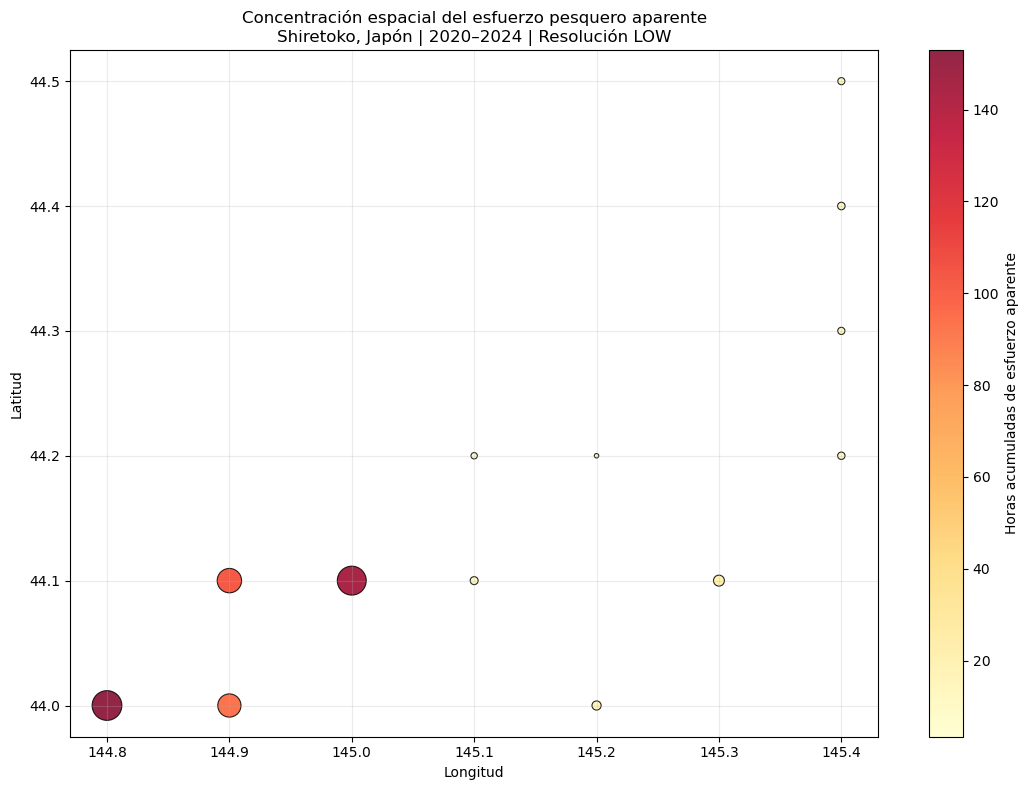

In [52]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Crear figura
fig, ax = plt.subplots(figsize=(11, 8))

# Gráfico espacial
scatter = ax.scatter(
    concentracion_espacial["lon"],
    concentracion_espacial["lat"],
    s=concentracion_espacial["horas_totales"] * 3,
    c=concentracion_espacial["horas_totales"],
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.8,
    alpha=0.85
)

# Barra de color
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Horas acumuladas de esfuerzo aparente")

# Etiquetas
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.set_title(
    "Concentración espacial del esfuerzo pesquero aparente\n"
    "Shiretoko, Japón | 2020–2024 | Resolución LOW"
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [53]:
import geopandas as gpd
import matplotlib.pyplot as plt

print("GeoPandas:", gpd.__version__)

GeoPandas: 1.2.0


In [54]:
# Cargar geometrías terrestres
world = gpd.read_file(
    "https://naturalearth.github.io/"
    "naturalearth_lowres/ne_110m_land.zip"
)

# Recortar la geometría a nuestra zona de estudio
zona = world.cx[144.5:145.8, 43.7:44.8]

print("Geometrías encontradas:", len(zona))

HTTPError: HTTP Error 404: Not Found

In [55]:
import os

print("ARCHIVOS DISPONIBLES:")
for archivo in os.listdir():
    print(archivo)


    
    

ARCHIVOS DISPONIBLES:
.ipynb_checkpoints
01_exploracion_area_estudio.ipynb
Prueba-2-GFW.ipynb
02_GFW_descarga_y_mapa.ipynb.ipynb
Shiretoko_EBSA_10401_10402.geojson


In [56]:
import geopandas as gpd

for nombre, objeto in globals().copy().items():
    if isinstance(objeto, gpd.GeoDataFrame):
        print(nombre, objeto.shape, objeto.crs)

shiretoko (2, 6) EPSG:4326
ebsa (2, 7) EPSG:4326
area_estudio (1, 3) EPSG:4326
ebsa_area (2, 6) EPSG:6933
union_area (1, 2) EPSG:6933
area_gfw (1, 2) EPSG:4326
area_utm (1, 2) EPSG:32655


In [57]:
# Inspeccionar las geometrías disponibles

objetos = [
    "shiretoko",
    "ebsa",
    "area_estudio",
    "ebsa_area",
    "union_area",
    "area_gfw",
    "area_utm"
]

for nombre in objetos:
    objeto = globals()[nombre]

    print(f"\n--- {nombre.upper()} ---")
    print("Columnas:", objeto.columns.tolist())
    print("Tipo de geometría:")
    print(objeto.geom_type.value_counts())
    print("Extensión espacial:")
    print(objeto.total_bounds)


--- SHIRETOKO ---
Columnas: ['AreaNumber', 'AreaName', 'Municipali', 'Area', 'URL', 'geometry']
Tipo de geometría:
MultiPolygon    2
Name: count, dtype: int64
Extensión espacial:
[144.78856639  43.78250393 145.48289701  44.48055712]

--- EBSA ---
Columnas: ['AreaNumber', 'AreaName', 'Municipali', 'Area', 'URL', 'geometry', 'area_km2']
Tipo de geometría:
MultiPolygon    2
Name: count, dtype: int64
Extensión espacial:
[144.78856639  43.78250393 145.48289701  44.48055712]

--- AREA_ESTUDIO ---
Columnas: ['nombre', 'geometry', 'area_km2']
Tipo de geometría:
MultiPolygon    1
Name: count, dtype: int64
Extensión espacial:
[144.78856639  43.78250393 145.48289701  44.48055712]

--- EBSA_AREA ---
Columnas: ['AreaNumber', 'AreaName', 'Municipali', 'Area', 'URL', 'geometry']
Tipo de geometría:
MultiPolygon    2
Name: count, dtype: int64
Extensión espacial:
[13970110.19364107  5068385.21163262 14037103.57226949  5132718.89370836]

--- UNION_AREA ---
Columnas: ['nombre', 'geometry']
Tipo de geomet

In [58]:
# Revisar los atributos de las geometrías originales

print("GEOMETRÍAS DE SHIRETOKO")

display(
    shiretoko[
        ["AreaNumber", "AreaName", "Municipali", "Area"]
    ]
)

print("\nGEOMETRÍAS DE EBSA")

display(
    ebsa[
        ["AreaNumber", "AreaName", "Municipali", "Area", "area_km2"]
    ]
)
print("\nCOMPARACIÓN DE GEOMETRÍAS")

print(
    "Shiretoko coincide con EBSA:",
    shiretoko.geometry.equals(ebsa.geometry)
)

print(
    "Área de estudio coincide con GFW:",
    area_estudio.geometry.equals(area_gfw.geometry)
)




GEOMETRÍAS DE SHIRETOKO


,AreaNumber,AreaName,Municipali,Area
0,10401.0,"Shiretoko (Shari, Utoro) side coast","Shari, Rausu, Hokkaido Prefecture",215.07212
1,10402.0,Shiretoko (Rausu) side coast,"Shibetsu, Rausu, Hokkaido Prefecture",323.24391



GEOMETRÍAS DE EBSA


,AreaNumber,AreaName,Municipali,Area,area_km2
0,10401.0,"Shiretoko (Shari, Utoro) side coast","Shari, Rausu, Hokkaido Prefecture",215.07212,215.033544
1,10402.0,Shiretoko (Rausu) side coast,"Shibetsu, Rausu, Hokkaido Prefecture",323.24391,323.247792



COMPARACIÓN DE GEOMETRÍAS


AttributeError: 'bool' object has no attribute 'all'

In [59]:
print("\nCOMPARACIÓN DE GEOMETRÍAS")

print(
    "Shiretoko coincide con EBSA:",
    shiretoko.geometry.equals(ebsa.geometry)
)

print(
    "Área de estudio coincide con GFW:",
    area_estudio.geometry.equals(area_gfw.geometry)
)



COMPARACIÓN DE GEOMETRÍAS
Shiretoko coincide con EBSA: True
Área de estudio coincide con GFW: True


In [60]:
print("GEOMETRÍAS DEL ARCHIVO ORIGINAL")

display(
    gpd.read_file("Shiretoko_EBSA_10401_10402.geojson")
)

GEOMETRÍAS DEL ARCHIVO ORIGINAL


,nombre,geometry
0,Shiretoko_EBSA_10401_10402,"MULTIPOLYGON (((145.38698 44.33965, 145.38617 ..."


In [61]:
import geopandas as gpd

try:
    world = gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
    print("Capa terrestre disponible")
except Exception as e:
    print("No está disponible:", e)

No está disponible: The geopandas.dataset has been deprecated and was removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.


In [62]:
# Descargar y cargar la geometría terrestre de Natural Earth

url_tierra = (
    "https://naciscdn.org/naturalearth/10m/physical/"
    "ne_10m_land.zip"
)

tierra = gpd.read_file(url_tierra)

print("CAPA TERRESTRE CARGADA")
print("CRS:", tierra.crs)
print("Dimensiones:", tierra.shape)
print("Tipo de geometría:")
print(tierra.geom_type.value_counts())

CAPA TERRESTRE CARGADA
CRS: EPSG:4326
Dimensiones: (11, 4)
Tipo de geometría:
MultiPolygon    10
Polygon          1
Name: count, dtype: int64


GEOMETRÍA TERRESTRE DE SHIRETOKO
Dimensiones: (2, 4)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

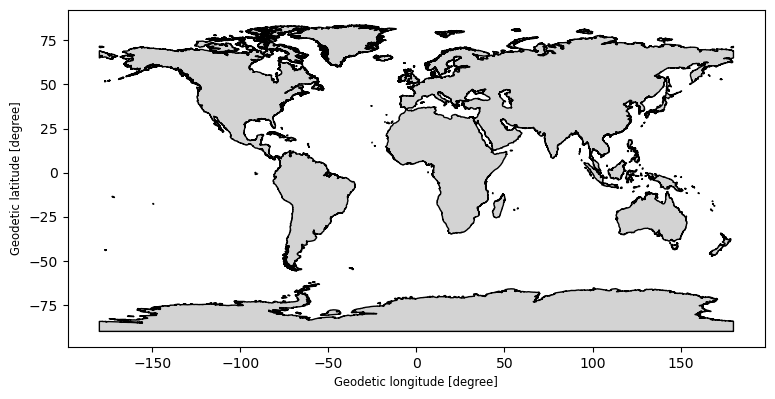

In [63]:
# Recortar la capa terrestre a Shiretoko

tierra_shiretoko = tierra.cx[
    144.5:145.8,
    43.7:44.8
]

print("GEOMETRÍA TERRESTRE DE SHIRETOKO")
print("Dimensiones:", tierra_shiretoko.shape)

tierra_shiretoko.plot(
    figsize=(9, 8),
    color="lightgray",
    edgecolor="black"
)

GEOMETRÍA TERRESTRE RECORTADA
Dimensiones: (2, 4)
CRS: EPSG:4326


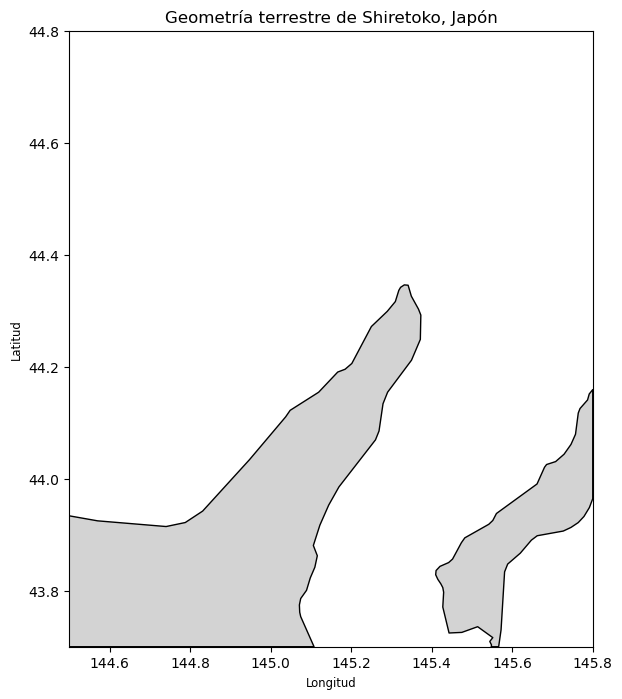

In [64]:
from shapely.geometry import box
import geopandas as gpd
import matplotlib.pyplot as plt

# Definir los límites de Shiretoko
limite_shiretoko = gpd.GeoDataFrame(
    geometry=[box(144.5, 43.7, 145.8, 44.8)],
    crs=tierra.crs
)

# Recortar las geometrías terrestres
tierra_shiretoko = gpd.clip(
    tierra,
    limite_shiretoko
)

print("GEOMETRÍA TERRESTRE RECORTADA")
print("Dimensiones:", tierra_shiretoko.shape)
print("CRS:", tierra_shiretoko.crs)

# Visualizar
fig, ax = plt.subplots(figsize=(9, 8))

tierra_shiretoko.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

ax.set_xlim(144.5, 145.8)
ax.set_ylim(43.7, 44.8)

ax.set_title("Geometría terrestre de Shiretoko, Japón")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

plt.show()

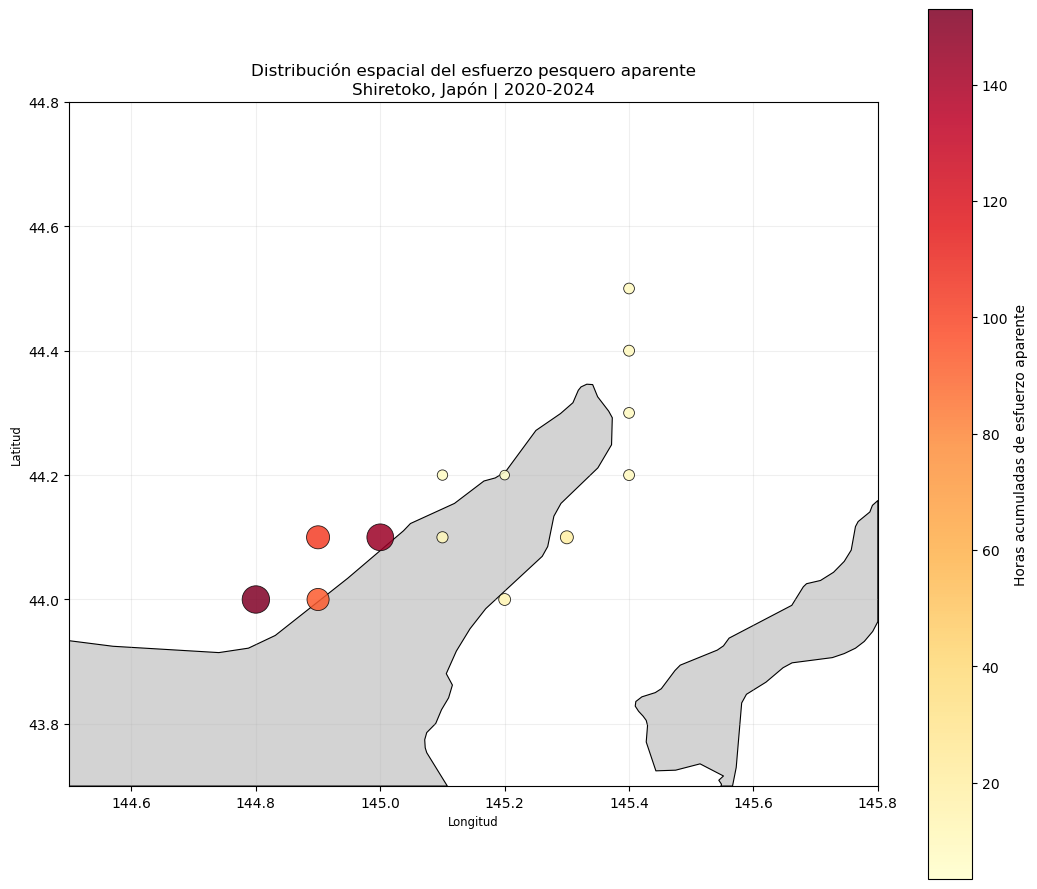

In [65]:
import matplotlib.pyplot as plt
import geopandas as gpd

# Crear figura
fig, ax = plt.subplots(figsize=(11, 9))

# Dibujar geometría terrestre
tierra_shiretoko.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.8,
    zorder=1
)

# Escala de los puntos según horas acumuladas
tamanos = (
    40 + 
    350 * concentracion_espacial["horas_totales"] /
    concentracion_espacial["horas_totales"].max()
)

# Graficar esfuerzo pesquero
puntos = ax.scatter(
    concentracion_espacial["lon"],
    concentracion_espacial["lat"],
    c=concentracion_espacial["horas_totales"],
    s=tamanos,
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.85,
    zorder=3
)

# Barra de color
cbar = plt.colorbar(puntos, ax=ax)
cbar.set_label("Horas acumuladas de esfuerzo aparente")

# Configuración cartográfica
ax.set_xlim(144.5, 145.8)
ax.set_ylim(43.7, 44.8)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.set_title(
    "Distribución espacial del esfuerzo pesquero aparente\n"
    "Shiretoko, Japón | 2020-2024"
)

ax.set_aspect("equal")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [66]:
from shapely.geometry import Point

# Unificar la geometría terrestre
tierra_union = tierra_shiretoko.geometry.unary_union

# Crear copia de los datos espaciales
puntos_revision = concentracion_espacial.copy()

# Identificar puntos
puntos_revision["en_tierra"] = puntos_revision.apply(
    lambda fila: tierra_union.intersects(
        Point(fila["lon"], fila["lat"])
    ),
    axis=1
)

# Resumen
print("REVISIÓN DE PUNTOS ESPACIALES")

print(
    puntos_revision["en_tierra"].value_counts()
)

print("\nPUNTOS QUE COINCIDEN CON TIERRA:")

display(
    puntos_revision[
        puntos_revision["en_tierra"]
    ].sort_values(
        "horas_totales",
        ascending=False
    )
)

REVISIÓN DE PUNTOS ESPACIALES
en_tierra
False    11
True      2
Name: count, dtype: int64

PUNTOS QUE COINCIDEN CON TIERRA:


/tmp/ipykernel_869/1157443972.py:4: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  tierra_union = tierra_shiretoko.geometry.unary_union


,lat,lon,horas_totales,registros,anios,meses,en_tierra
5,44.1,145.1,10.966389,5,2,5,True
8,44.2,145.2,3.429444,1,1,1,True


In [67]:
# Comparación de esfuerzo con y sin puntos coincidentes con tierra

resumen_revision = (
    puntos_revision
    .groupby("en_tierra")
    .agg(
        ubicaciones=("horas_totales", "count"),
        horas=("horas_totales", "sum"),
        registros=("registros", "sum")
    )
)

total_horas = puntos_revision["horas_totales"].sum()

resumen_revision["porcentaje_horas"] = (
    resumen_revision["horas"] / total_horas * 100
)

print("COMPARACIÓN ESPACIAL")
display(resumen_revision)

print("\nESFUERZO TOTAL ORIGINAL:")
print(round(total_horas, 2), "horas")

print("\nESFUERZO SIN PUNTOS COINCIDENTES CON TIERRA:")
print(round(
    puntos_revision.loc[
        ~puntos_revision["en_tierra"],
        "horas_totales"
    ].sum(), 2
), "horas")

COMPARACIÓN ESPACIAL


,ubicaciones,horas,registros,porcentaje_horas
en_tierra,,,,
False,11,572.924892,61,97.548897
True,2,14.395833,6,2.451103



ESFUERZO TOTAL ORIGINAL:
587.32 horas

ESFUERZO SIN PUNTOS COINCIDENTES CON TIERRA:
572.92 horas


In [68]:
# ==========================================
# 1. COMPARACIÓN ANUAL DEL ESFUERZO PESQUERO
# ==========================================

df_comparativo = df_consolidado.copy()

# Asegurar formato de fecha
df_comparativo["date"] = pd.to_datetime(
    df_comparativo["date"],
    errors="coerce"
)

# Extraer año y mes
df_comparativo["anio"] = df_comparativo["date"].dt.year
df_comparativo["mes"] = df_comparativo["date"].dt.month

# Resumen anual
resumen_anual = (
    df_comparativo
    .groupby("anio")
    .agg(
        horas_totales=("hours", "sum"),
        registros=("hours", "count"),
        meses_activos=("mes", "nunique"),
        promedio_horas=("hours", "mean")
    )
    .reset_index()
)

# Calcular porcentaje del esfuerzo total
resumen_anual["porcentaje_esfuerzo"] = (
    resumen_anual["horas_totales"] /
    resumen_anual["horas_totales"].sum()
) * 100

# Mostrar resultados
print("COMPARACIÓN ANUAL DEL ESFUERZO PESQUERO")
display(resumen_anual.round(2))

COMPARACIÓN ANUAL DEL ESFUERZO PESQUERO


,anio,horas_totales,registros,meses_activos,promedio_horas,porcentaje_esfuerzo
0,2020,92.14,5,3,18.43,15.69
1,2021,7.45,2,1,3.73,1.27
2,2022,29.19,11,6,2.65,4.97
3,2023,302.83,24,8,12.62,51.56
4,2024,155.71,25,7,6.23,26.51


In [69]:
# ==========================================
# 2. DISTRIBUCIÓN MENSUAL DEL ESFUERZO
# ==========================================

esfuerzo_mensual = (
    df_comparativo
    .groupby(["anio", "mes"])
    .agg(
        horas_totales=("hours", "sum"),
        registros=("hours", "count")
    )
    .reset_index()
)

# Tabla comparativa: años vs meses
tabla_mensual = esfuerzo_mensual.pivot(
    index="mes",
    columns="anio",
    values="horas_totales"
).fillna(0)

print("HORAS DE ESFUERZO POR MES Y AÑO")
display(tabla_mensual.round(2))

HORAS DE ESFUERZO POR MES Y AÑO


anio,2020,2021,2022,2023,2024
mes,,,,,
4,52.05,7.45,0.00,5.96,10.32
5,0.00,0.00,0.00,4.97,5.80
6,0.00,0.00,4.81,34.17,4.53
7,0.97,0.00,2.33,174.19,34.92
8,0.00,0.00,0.49,56.35,59.30
9,39.12,0.00,0.00,2.65,9.03
10,0.00,0.00,6.01,4.18,31.81
11,0.00,0.00,2.67,0.00,0.00
12,0.00,0.00,12.88,20.36,0.00


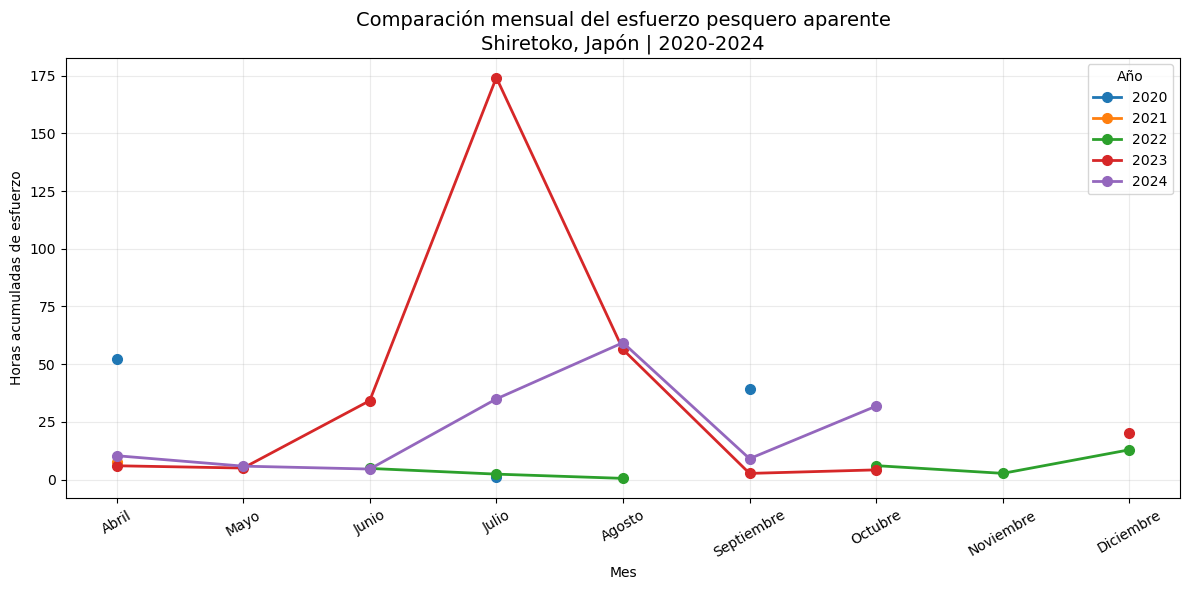

In [70]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preparar los datos
df_mensual = df_consolidado.copy()

df_mensual["date"] = pd.to_datetime(
    df_mensual["date"].astype(str)
)

df_mensual["anio"] = df_mensual["date"].dt.year
df_mensual["mes"] = df_mensual["date"].dt.month

# Sumar horas por mes y año
tabla_mensual = df_mensual.pivot_table(
    index="mes",
    columns="anio",
    values="hours",
    aggfunc="sum"
)

# Mantener los meses de abril a diciembre
tabla_mensual = tabla_mensual.reindex(range(4, 13))

# Etiquetas de meses
nombres_meses = {
    4: "Abril", 5: "Mayo", 6: "Junio",
    7: "Julio", 8: "Agosto", 9: "Septiembre",
    10: "Octubre", 11: "Noviembre", 12: "Diciembre"
}

# Construir gráfica
plt.figure(figsize=(12, 6))

for anio in tabla_mensual.columns:
    plt.plot(
        tabla_mensual.index,
        tabla_mensual[anio],
        marker="o",
        linewidth=2,
        markersize=7,
        label=str(anio)
    )

plt.xticks(
    range(4, 13),
    [nombres_meses[m] for m in range(4, 13)],
    rotation=30
)

plt.title(
    "Comparación mensual del esfuerzo pesquero aparente\n"
    "Shiretoko, Japón | 2020-2024",
    fontsize=14
)

plt.xlabel("Mes")
plt.ylabel("Horas acumuladas de esfuerzo")
plt.grid(alpha=0.25)
plt.legend(title="Año")
plt.tight_layout()
plt.show()


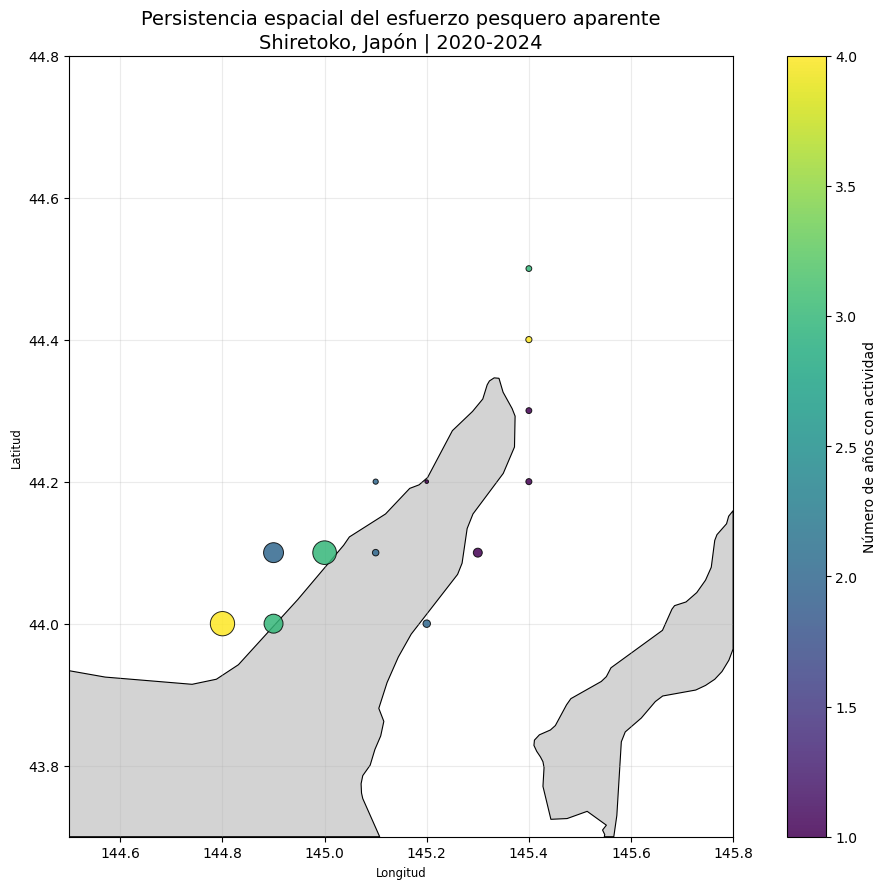

In [71]:

# Agrupar información por ubicación
persistencia = (
    df_consolidado
    .groupby(["lat", "lon"])
    .agg(
        horas_totales=("hours", "sum"),
        anios_activos=("anio", "nunique"),
        registros=("date", "count"),
        meses_activos=("date", "nunique")
    )
    .reset_index()
)

# Crear figura
fig, ax = plt.subplots(figsize=(11, 9))

# Dibujar geometría terrestre
tierra_shiretoko.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.8,
    zorder=1
)

# Dibujar ubicaciones
puntos = ax.scatter(
    persistencia["lon"],
    persistencia["lat"],
    c=persistencia["anios_activos"],
    s=persistencia["horas_totales"] * 2,
    cmap="viridis",
    alpha=0.85,
    edgecolor="black",
    linewidth=0.7,
    zorder=3
)

# Barra de color
cbar = plt.colorbar(puntos, ax=ax)
cbar.set_label("Número de años con actividad")

# Configuración
ax.set_xlim(144.5, 145.8)
ax.set_ylim(43.7, 44.8)

ax.set_title(
    "Persistencia espacial del esfuerzo pesquero aparente\n"
    "Shiretoko, Japón | 2020-2024",
    fontsize=14
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [72]:

print("PERSISTENCIA ESPACIAL POR UBICACIÓN")

display(
    persistencia.sort_values(
        ["anios_activos", "horas_totales"],
        ascending=False
    ).round(2)
)


PERSISTENCIA ESPACIAL POR UBICACIÓN


,lat,lon,horas_totales,anios_activos,registros,meses_activos
0,44.0,144.8,152.98,4,14,14
11,44.4,145.4,9.82,4,6,6
4,44.1,145.0,144.76,3,12,12
1,44.0,144.9,93.24,3,9,9
12,44.5,145.4,8.69,3,8,8
3,44.1,144.9,102.79,2,5,5
2,44.0,145.2,14.51,2,2,2
5,44.1,145.1,10.97,2,5,5
7,44.2,145.1,7.01,2,2,2
6,44.1,145.3,20.72,1,1,1


In [73]:

# Recalcular persistencia espacial

df_temp = df_consolidado.copy()

df_temp["date"] = pd.to_datetime(
    df_temp["date"].astype(str)
)

df_temp["mes"] = df_temp["date"].dt.month

persistencia = (
    df_temp.groupby(["lat", "lon"])
    .agg(
        horas_totales=("hours", "sum"),
        anios_activos=("anio", "nunique"),
        registros=("date", "count"),
        periodos_activos=("date", "nunique"),
        meses_calendario=("mes", "nunique")
    )
    .reset_index()
)

display(
    persistencia.sort_values(
        ["anios_activos", "horas_totales"],
        ascending=False
    ).round(2)
)


,lat,lon,horas_totales,anios_activos,registros,periodos_activos,meses_calendario
0,44.0,144.8,152.98,4,14,14,8
11,44.4,145.4,9.82,4,6,6,4
4,44.1,145.0,144.76,3,12,12,7
1,44.0,144.9,93.24,3,9,9,6
12,44.5,145.4,8.69,3,8,8,5
3,44.1,144.9,102.79,2,5,5,3
2,44.0,145.2,14.51,2,2,2,2
5,44.1,145.1,10.97,2,5,5,5
7,44.2,145.1,7.01,2,2,2,2
6,44.1,145.3,20.72,1,1,1,1
